# Statistical screens

Z-scores, IQR fences, and modified z-scores are review aids. Benford's Law is applied to a filtered invoice population and, separately, to capped expense claims as a contrast. A digit deviation is not a fraud finding.

Vendor risk is the weighted score already stored by the pipeline. This notebook reads that output and recomputes the Benford and outlier screens from the raw files.

In [1]:
import sys
from pathlib import Path
root = Path.cwd().resolve()
if root.name == 'notebooks':
    root = root.parent
sys.path.insert(0, str(root))


In [2]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
from src.utils.config import load_config
from src.utils.frames import read_operational_tables
from src.reporting.statistics import expense_benford, invoice_benford, statistical_outliers

config = load_config()
root = Path(config['_project_root'])
tables = read_operational_tables(root / 'data' / 'raw')
invoice_screen = invoice_benford(tables['invoices'], config)
expense_screen = expense_benford(tables['employee_expenses'], config)
pd.DataFrame([
    {key: invoice_screen[key] for key in ('population', 'sample_size', 'applicable', 'mad', 'p_value', 'conformity_band')},
    {key: expense_screen[key] for key in ('population', 'sample_size', 'applicable', 'mad', 'p_value', 'conformity_band')},
])

,population,sample_size,applicable,mad,p_value,conformity_band
0,non_recurring_invoices,875,True,0.014080,7.198302e-04,marginal_conformity
1,employee_expenses,815,True,0.018994,4.869991e-09,nonconformity


In [3]:
invoice_screen['distribution']

,population,digit,observed_count,observed_share,expected_share,expected_count,absolute_deviation
0,non_recurring_invoices,1,278,0.317714,0.301030,263.4012,0.016684
1,non_recurring_invoices,2,165,0.188571,0.176091,154.0799,0.012480
2,non_recurring_invoices,3,98,0.112000,0.124939,109.3214,0.012939
3,non_recurring_invoices,4,71,0.081143,0.096910,84.7963,0.015767
4,non_recurring_invoices,5,86,0.098286,0.079181,69.2836,0.019104
5,non_recurring_invoices,6,55,0.062857,0.066947,58.5784,0.004090
6,non_recurring_invoices,7,24,0.027429,0.057992,50.7430,0.030563
7,non_recurring_invoices,8,46,0.052571,0.051153,44.7585,0.001419
8,non_recurring_invoices,9,52,0.059429,0.045757,40.0378,0.013671


Mean absolute deviation bands follow a common audit heuristic (close, acceptable, marginal, nonconformity). They are not a legal or statistical proof of fraud. Capped, priced-from-a-catalogue, or recurring amounts are poor Benford populations.
Employee expenses are bounded by category thresholds and receipt rules. A Benford deviation in this population is expected to be ambiguous and is not used as an alert.


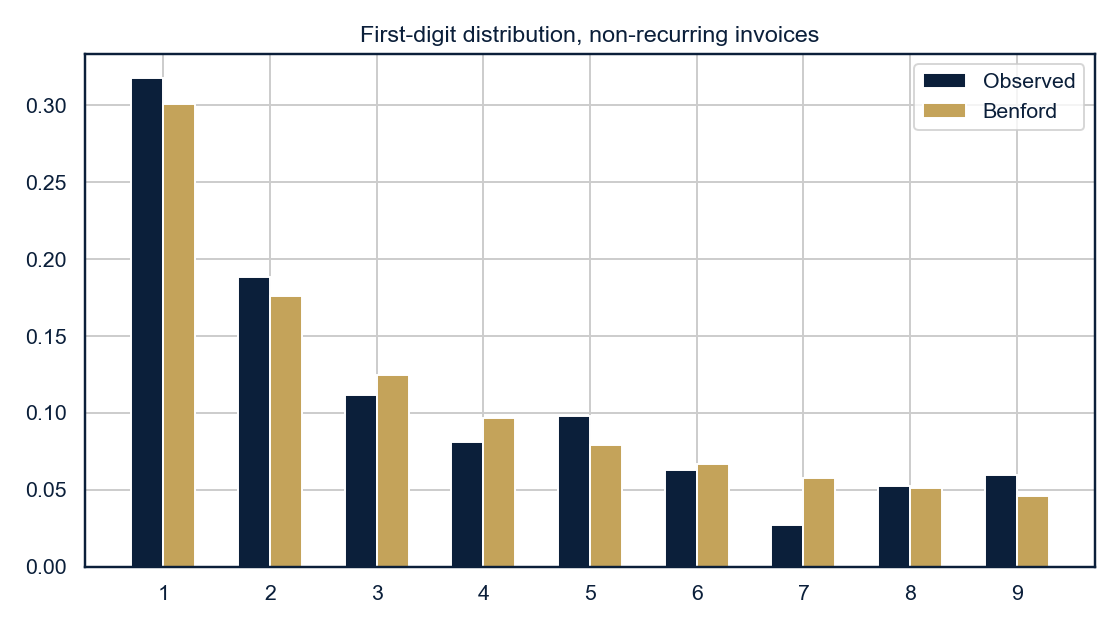

In [4]:
print(invoice_screen['limitation'])
print(expense_screen['limitation'])
display(Image(filename=str(root / 'screenshots' / '05_benford_invoices.png')))

In [5]:
outliers = statistical_outliers(tables['invoices'], tables['vendors'], config)
print('outlier_rows', len(outliers))
outliers.head(10)

outlier_rows 250


,invoice_id,vendor_id,vendor_category,total_amount_inr,group_size,z_score,modified_z_score,iqr_outlier,zscore_outlier,modified_z_outlier,note
0,INV000337,VEN023,Equipment,181000.0,152,1.6080,7.4245,True,False,True,Statistical outlier inside the vendor category...
1,INV000338,VEN023,Equipment,189500.0,152,1.7222,7.8261,True,False,True,Statistical outlier inside the vendor category...
2,INV000339,VEN023,Equipment,197000.0,152,1.8230,8.1804,True,False,True,Statistical outlier inside the vendor category...
3,INV000340,VEN024,Equipment,181000.0,152,1.6080,7.4245,True,False,True,Statistical outlier inside the vendor category...
4,INV000341,VEN024,Equipment,189500.0,152,1.7222,7.8261,True,False,True,Statistical outlier inside the vendor category...
5,INV000342,VEN024,Equipment,197000.0,152,1.8230,8.1804,True,False,True,Statistical outlier inside the vendor category...
6,INV000343,VEN025,Equipment,181000.0,152,1.6080,7.4245,True,False,True,Statistical outlier inside the vendor category...
7,INV000344,VEN025,Equipment,189500.0,152,1.7222,7.8261,True,False,True,Statistical outlier inside the vendor category...
8,INV000345,VEN025,Equipment,197000.0,152,1.8230,8.1804,True,False,True,Statistical outlier inside the vendor category...
9,INV000346,VEN026,Equipment,181000.0,152,1.6080,7.4245,True,False,True,Statistical outlier inside the vendor category...


The risk table is the pipeline output. Isolation Forest flags are a comparison column and are not part of the score.

In [6]:
scores = pd.read_csv(root / 'data' / 'processed' / 'vendor_risk_scores.csv')
print(scores['risk_category'].value_counts().to_string())
print('max_score', scores['risk_score'].max())
scores[['vendor_id', 'vendor_name', 'risk_score', 'risk_category', 'explanation']].head(8)

risk_category
Low       52
Medium     8
max_score 34.38


,vendor_id,vendor_name,risk_score,risk_category,explanation
0,VEN044,Boase-Mallick,34.38,Medium,Score 34.38 (Medium). duplicate invoices 7.72 ...
1,VEN040,Iyengar Group,31.48,Medium,Score 31.48 (Medium). duplicate invoices 9.46 ...
2,VEN038,Dutta-Chokshi,28.22,Medium,Score 28.22 (Medium). duplicate invoices 12.22...
3,VEN041,Mody-Kari,28.14,Medium,Score 28.14 (Medium). duplicate invoices 7.15 ...
4,VEN042,Bajwa Ltd,27.08,Medium,Score 27.08 (Medium). duplicate invoices 9.46 ...
5,VEN032,Parmar and Sons,26.80,Medium,Score 26.80 (Medium). duplicate invoices 11.73...
6,VEN043,Rastogi LLC,26.10,Medium,Score 26.10 (Medium). duplicate invoices 8.63 ...
7,VEN047,Lal and Sons,25.98,Medium,Score 25.98 (Medium). duplicate invoices 0.00 ...


In [7]:
metrics = pd.read_csv(root / 'data' / 'evaluation' / 'rule_metrics.csv')
print('unweighted_mean_f1', round(float(metrics['f1_score'].mean()), 4))
metrics[['rule_code', 'precision', 'recall', 'f1_score', 'false_positives', 'false_negatives', 'benign_controls_flagged']]

unweighted_mean_f1 0.9584


,rule_code,precision,recall,f1_score,false_positives,false_negatives,benign_controls_flagged
0,EXACT_DUP_INVOICE,1.000000,1.000000,1.000000,0,0,0
1,NEAR_TIME_DUP_INVOICE,1.000000,0.714286,0.833333,0,8,0
2,FUZZY_DUP_INVOICE,1.000000,1.000000,1.000000,0,0,0
3,SPLIT_PURCHASE,1.000000,1.000000,1.000000,0,0,0
4,THRESHOLD_GAMING,1.000000,1.000000,1.000000,0,0,0
5,DUP_PAYMENT,1.000000,1.000000,1.000000,0,0,0
6,EARLY_PAYMENT,0.625000,1.000000,0.769231,3,0,3
7,LATE_PAYMENT,0.714286,1.000000,0.833333,6,0,6
8,PAYMENT_MISMATCH,1.000000,1.000000,1.000000,0,0,0
9,DUPLICATE_EXPENSE,1.000000,1.000000,1.000000,0,0,0
